In [2]:
import pandas as pd
import numpy as np
from tqdm.auto import tqdm
import subprocess as sbp
import matplotlib.pyplot as plt
import seaborn as sns
from joblib import delayed, Parallel


def sample_configurations(n, k, initial_configuration, bias=1.0, samples=100, seed=231):
    if bias != 1.0:
        cmd = f"ewens-sampler sample --seed {seed} -n {n} -k {k} --initial-configuration '{initial_configuration}' --bias {bias} -c tabular {int(samples)}"
    else:
        cmd = f"ewens-sampler sample --seed {seed} -n {n} -k {k} --initial-configuration '{initial_configuration}' -c tabular {int(samples)}"

    s = sbp.getoutput(cmd).split("\n")
    return s


def run_test(n, k, configuration, samples=1e8, seed=233):
    cmd = f"ewens-sampler sample --seed {seed} -n {n} -k {k} {int(samples)} | ewens-sampler test '{configuration}'"

    result = sbp.getoutput(cmd).split()
    count, total = int(result[0]), int(result[1])

    return count / total


def run_test_conditional(
    n, k, configuration, initial_configuration, samples=1e8, seed=234
):
    cmd = f"ewens-sampler sample --seed {seed} -n {n} -k {k} --initial-configuration '{initial_configuration}' {int(samples)} | ewens-sampler test '{configuration}'"

    result = sbp.getoutput(cmd).split()
    count, total = int(result[0]), int(result[1])

    return count / total

In [23]:
d = pd.read_csv("popes-list.csv")
start_idx = d.query("start > 1045").index.min()
end_idx = d.query("start >= 1245").index.min()

In [24]:
d_start = d.iloc[:start_idx]
ic = " ".join([str(x) for x in d_start["name"].value_counts()])

inputs = []
grng = np.random.default_rng(123)

for i in range(start_idx + 1, end_idx + 1):
    d_end = d.iloc[:i]
    n = d_end.shape[0]
    k = len(d_end["name"].unique())
    inputs.append((n, k, ic, grng.choice(int(1e6))))

In [25]:
def run(n, k, ic, seed):
    rng = np.random.default_rng(seed)

    rows = []
    for b in [0.5, 0.8, 0.9, 1.0, 1.11, 1.25, 2]:
        for tc in sample_configurations(
            n, k, ic, bias=b, samples=100, seed=rng.choice(int(1e6))
        ):
            pval = run_test_conditional(n, k, tc, ic, samples=100000)

            rows.append({"bias": b, "n": n, "k": k, "tc": tc, "pval": pval})

    return pd.DataFrame.from_records(rows)

In [15]:
results = Parallel(n_jobs=-1)(delayed(run)(*args) for args in inputs)
pvals = pd.concat(results)

In [ ]:
d = pd.read_csv("popes-list.csv")
dpv = pvals.merge(d.reset_index(), how="left", left_on="n", right_on="index").drop(
    columns=["index", "name"]
)

In [43]:
real_configs = []

for i in range(start_idx + 1, end_idx + 1):
    d_end = d.iloc[:i]
    n = d_end.shape[0]
    k = len(d_end["name"].unique())
    c = " ".join([str(x) for x in d_end["name"].value_counts()])
    real_configs.append((n, k, c, ic, grng.choice(int(1e6))))

ans = Parallel(n_jobs=-1)(
    delayed(run_test_conditional)(n, k, c, ic, samples=100000, seed=s)
    for (n, k, c, ic, s) in real_configs
)

In [47]:
dpv_real = pd.DataFrame({"n": [x[0] for x in real_configs], "pval_real": ans})
dpv_all = dpv.merge(dpv_real, how="left", on="n")

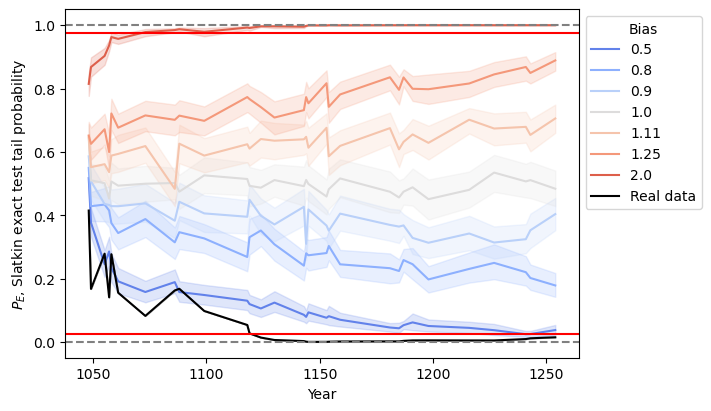

In [52]:
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)

sns.lineplot(
    dpv_all,
    x="start",
    y="pval",
    hue="bias",
    palette=sns.color_palette("coolwarm", n_colors=7),
    ax=ax,
)
sns.lineplot(dpv_all, x="start", y="pval_real", color="black", ax=ax, label="Real data")

ax.legend(loc="upper left", bbox_to_anchor=(1, 1), title="Bias")


ax.set_xlabel("Year")
ax.set_ylabel("$P_E$, Slatkin exact test tail probability")
ax.axhline(0.025, color="red")
ax.axhline(0.975, color="red")
ax.axhline(1, color="gray", linestyle="--")
ax.axhline(0, color="gray", linestyle="--")

fig.savefig("biased_sim_year.pdf", bbox_inches="tight")
fig.savefig("biased_sim_year.png", bbox_inches="tight", dpi=600)

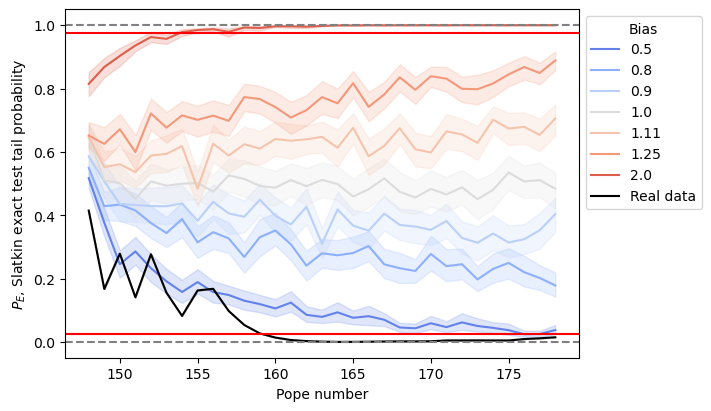

In [53]:
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)

sns.lineplot(
    dpv_all,
    x="n",
    y="pval",
    hue="bias",
    palette=sns.color_palette("coolwarm", n_colors=7),
    ax=ax,
)
sns.lineplot(dpv_all, x="n", y="pval_real", color="black", ax=ax, label="Real data")

ax.legend(loc="upper left", bbox_to_anchor=(1, 1), title="Bias")


ax.set_xlabel("Pope number")
ax.set_ylabel("$P_E$, Slatkin exact test tail probability")
ax.axhline(0.025, color="red")
ax.axhline(0.975, color="red")
ax.axhline(1, color="gray", linestyle="--")
ax.axhline(0, color="gray", linestyle="--")

fig.savefig("biased_sim_n.pdf", bbox_inches="tight")
fig.savefig("biased_sim_n.png", bbox_inches="tight", dpi=600)

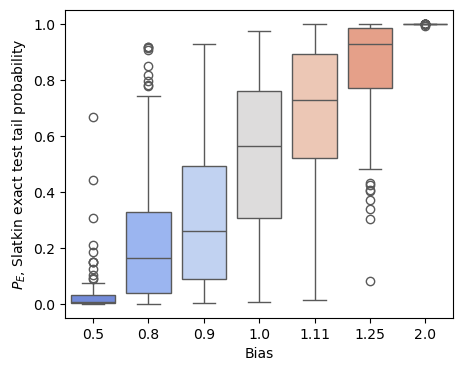

In [57]:
fig, ax = plt.subplots(figsize=(5, 4))

sns.boxplot(
    dpv_all.query("n==175"),
    x="bias",
    y="pval",
    hue="bias",
    palette=sns.color_palette("coolwarm", n_colors=7),
    ax=ax,
    legend=False,
)
ax.set_xlabel("Bias")
ax.set_ylabel("$P_E$, Slatkin exact test tail probability")

fig.savefig("biased_sim_box_175.pdf", bbox_inches="tight")
fig.savefig("biased_sim_box_175.png", bbox_inches="tight", dpi=600)

In [71]:
dpv_all.to_csv("biased_simulations.csv")

In [76]:
popes = pd.read_csv("popes-list.csv")


def get_windows(size):
    x = np.arange(432, 2025 - size + 1)
    return zip(x, x + size)


windows = [(x, x + 200) for x in popes.query("start >= 432 and start < 1830")["start"]]


def run_sim(popes, s, e):
    d = popes.query("start <= @s")

    year = d["start"].iloc[-1]
    pope = d["pope"].iloc[-1]
    ic = " ".join([str(x) for x in d["name"].value_counts()])
    n0 = d.shape[0]
    k0 = len(d["name"].unique())

    d_end = popes.query("start < @e")
    n = d_end.shape[0]
    k = len(d_end["name"].unique())

    tcs = sample_configurations(n, k, ic, bias=1.0, samples=100, seed=e)

    rows = []

    for tc in tcs:
        pval = run_test_conditional(n, k, tc, ic, samples=100000)
        rows.append(
            {
                "n": n,
                "k": k,
                "tc": tc,
                "pval": pval,
                "year": year,
                "pope": "pope",
                "n0": n0,
                "k0": k0,
            }
        )

    return pd.DataFrame.from_records(rows)

In [77]:
results = Parallel(n_jobs=-1)(delayed(run_sim)(popes, s, e) for (s, e) in tqdm(windows))

  0%|          | 0/208 [00:00<?, ?it/s]

In [80]:
d_longsim = pd.concat(results)
d_longsim.to_csv("neutral_longsim.parquet")

In [81]:
d_longsim

,n,k,tc,pval,year,pope,n0,k0
0,70,58,1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 ...,0.92039,432,pope,44,42
1,70,58,1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 ...,0.38921,432,pope,44,42
2,70,58,1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 ...,0.83644,432,pope,44,42
3,70,58,1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 ...,0.68131,432,pope,44,42
4,70,58,1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 ...,0.10204,432,pope,44,42
...,...,...,...,...,...,...,...,...
95,265,81,1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 ...,0.43467,1829,pope,251,79
96,265,81,1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 ...,0.92907,1829,pope,251,79
97,265,81,1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 ...,0.90265,1829,pope,251,79
98,265,81,1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 ...,0.24483,1829,pope,251,79


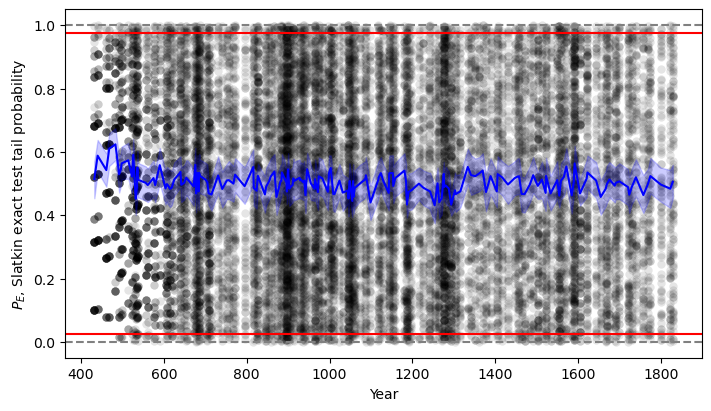

In [91]:
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)

sns.scatterplot(
    d_longsim, x="year", y="pval", color="black", alpha=0.1, ax=ax, linewidth=0
)
sns.lineplot(d_longsim, x="year", y="pval", color="blue", ax=ax)

ax.set_xlabel("Year")
ax.set_ylabel("$P_E$, Slatkin exact test tail probability")
ax.axhline(0.025, color="red")
ax.axhline(0.975, color="red")
ax.axhline(1, color="gray", linestyle="--")
ax.axhline(0, color="gray", linestyle="--")

fig.savefig("neutral_sim_year.pdf", bbox_inches="tight")
fig.savefig("neutral_sim_year.png", bbox_inches="tight", dpi=600)

In [37]:
def run_test_conditional_biased(
    n, k, configuration, initial_configuration, bias=1.0, samples=1e8, seed=234
):
    if bias == 1.0:
        bstr = ""
    else:
        bstr = f"-b {bias} "
    cmd = f"ewens-sampler sample --seed {seed} -n {n} -k {k} {bstr}--initial-configuration '{initial_configuration}' {int(samples)} | ewens-sampler test '{configuration}'"

    result = sbp.getoutput(cmd).split()
    count, total = int(result[0]), int(result[1])

    return count / total


def run_grid(n, k, ic, b_gen, b_test, samples=10000):
    rng = np.random.default_rng(int(n + k + 100 * b_gen + 100 * b_test))

    rows = []
    for tc in sample_configurations(
        n, k, ic, bias=b_gen, samples=100, seed=rng.choice(int(1e6))
    ):
        pval = run_test_conditional_biased(
            n, k, tc, ic, bias=b_test, samples=samples, seed=rng.choice(int(1e6))
        )

        rows.append(
            {"bias_gen": b_gen, "bias_test": b_test, "n": n, "k": k, "pval": pval}
        )

    return pd.DataFrame.from_records(rows)

In [38]:
d = pd.read_csv("popes-list.csv")
start_idx = d.query("start > 1045").index.min()
end_200_idx = d.query("start >= 1245").index.min()
end_500_idx = d.query("start >= 1545").index.min()

d_start = d.iloc[:start_idx]
ic = " ".join([str(x) for x in d_start["name"].value_counts()])


d_end = d.iloc[:end_200_idx]
n_200 = d_end.shape[0]
k_200 = len(d_end["name"].unique())

d_end = d.iloc[:end_500_idx]
n_500 = d_end.shape[0]
k_500 = len(d_end["name"].unique())

In [40]:
bias_grid = [
    (x, y)
    for x in [0.5, 0.8, 0.9, 1.0, 1.11, 1.25, 2]
    for y in [0.5, 0.8, 0.9, 1.0, 1.11, 1.25, 2]
]

results_200 = list(
    tqdm(
        Parallel(n_jobs=-1, return_as="generator")(
            delayed(run_grid)(n_200, k_200, ic, bg, bt) for (bg, bt) in bias_grid
        ),
        total=len(bias_grid),
    )
)
results_500 = list(
    tqdm(
        Parallel(n_jobs=-1, return_as="generator")(
            delayed(run_grid)(n_500, k_500, ic, bg, bt) for (bg, bt) in bias_grid
        ),
        total=len(bias_grid),
    )
)

  0%|          | 0/49 [00:00<?, ?it/s]

  0%|          | 0/49 [00:00<?, ?it/s]

In [42]:
ans = pd.concat(results_200 + results_500)
ans.to_csv("varbias_test_simulations.csv", index=False)
ans

,bias_gen,bias_test,n,k,pval
0,0.5,0.5,178,79,0.3343
1,0.5,0.5,178,79,0.9392
2,0.5,0.5,178,79,0.6738
3,0.5,0.5,178,79,0.9804
4,0.5,0.5,178,79,0.5746
...,...,...,...,...,...
95,2.0,2.0,218,79,0.9734
96,2.0,2.0,218,79,0.5419
97,2.0,2.0,218,79,0.2721
98,2.0,2.0,218,79,0.3742


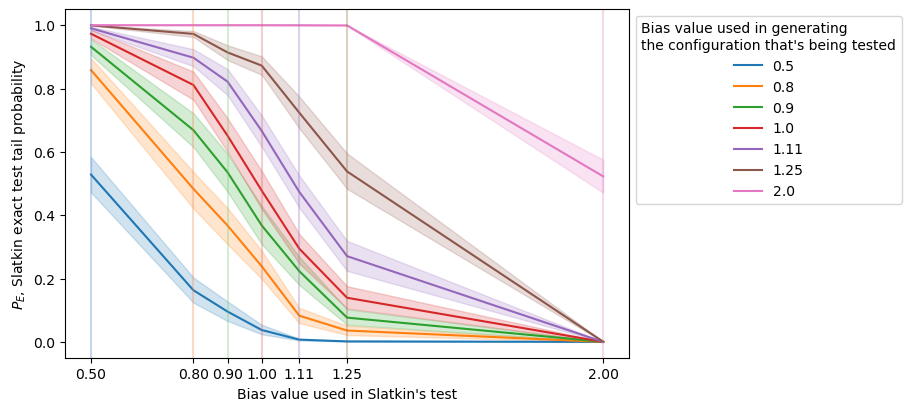

In [49]:
ans = pd.read_csv("varbias_test_simulations.csv").query("n == 178")
ans["bias_gen"] = ans["bias_gen"].astype(str)

palette = sns.color_palette("muted", n_colors=7)

fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
sns.lineplot(ans, x="bias_test", y="pval", hue="bias_gen", ax=ax)

biases = sorted(set(ans["bias_test"]))
for i, x in enumerate(biases):
    ax.axvline(x=float(x), color=palette[i], alpha=0.3)

ax.set_xlabel("Bias value used in Slatkin's test")
ax.set_ylabel("$P_E$, Slatkin exact test tail probability")
ax.set_xticks(biases)
ax.legend(
    title=("Bias value used in generating\nthe configuration that's being tested"),
    loc="upper left",
    bbox_to_anchor=(1, 1),
)

fig.savefig("bias_grid.pdf", bbox_inches="tight")
fig.savefig("bias_grid.png", dpi=600, bbox_inches="tight")

In [9]:
def onetail(x, alpha=0.05):
    return x[x < alpha].shape[0]


def twotail(x, alpha=0.05):
    return x[(x < alpha / 2) | (x > (1 - alpha / 2))].shape[0]


power_df = (
    pd.read_csv("varbias_test_simulations.csv")
    .groupby(["bias_gen", "bias_test", "n", "k"])
    .agg({"pval": ["count", onetail, twotail]})
    .reset_index()
)
power_df.columns = ["bias_gen", "bias_test", "n", "k", "total", "onetail", "twotail"]
power_df["onetail"] = power_df["onetail"] / power_df["total"]
power_df["twotail"] = power_df["twotail"] / power_df["total"]

power_df["bias_gen"] = power_df["bias_gen"].astype(str)
power_df

,bias_gen,bias_test,n,k,total,onetail,twotail
0,0.5,0.50,178,79,100,0.06,0.11
1,0.5,0.50,218,79,100,0.04,0.07
2,0.5,0.80,178,79,100,0.40,0.27
3,0.5,0.80,218,79,100,0.62,0.52
4,0.5,0.90,178,79,100,0.59,0.48
...,...,...,...,...,...,...,...
93,2.0,1.11,218,79,100,0.00,1.00
94,2.0,1.25,178,79,100,0.00,1.00
95,2.0,1.25,218,79,100,0.00,1.00
96,2.0,2.00,178,79,100,0.05,0.06


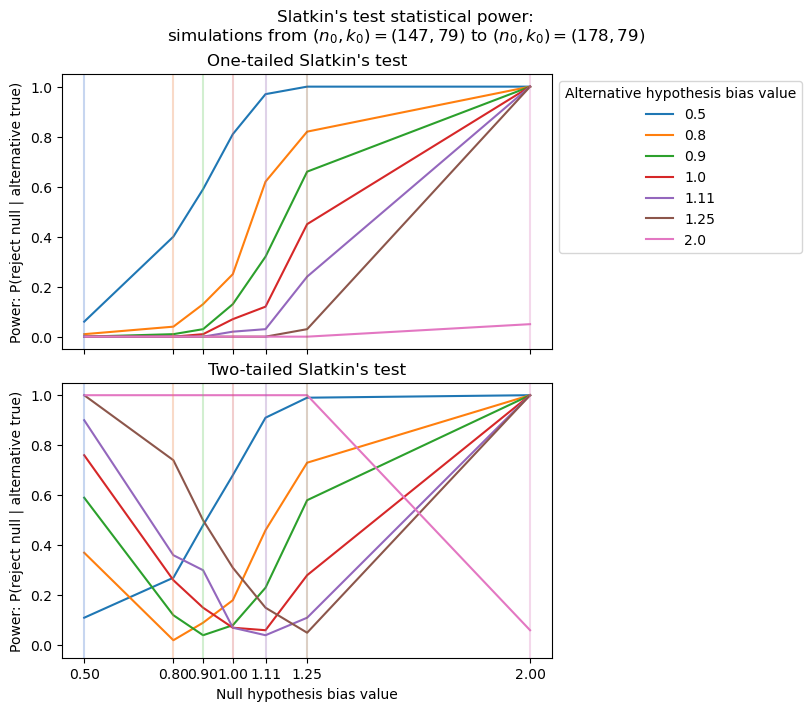

In [51]:
dplot = power_df.query("n == 178")
palette = sns.color_palette("muted", n_colors=7)
fig, axs = plt.subplots(
    2, 1, figsize=(8, 7), constrained_layout=True, sharex=True, sharey=True
)

ax = axs[0]
sns.lineplot(dplot, x="bias_test", y="onetail", hue="bias_gen", ax=ax)

biases = sorted(set(dplot["bias_test"]))
for i, x in enumerate(biases):
    ax.axvline(x=float(x), color=palette[i], alpha=0.3)

ax.set_xlabel("Null hypothesis bias value")
ax.set_ylabel("Power: P(reject null | alternative true)")
ax.set_xticks(biases)
ax.legend(
    title=("Alternative hypothesis bias value"), loc="upper left", bbox_to_anchor=(1, 1)
)
ax.set_title("One-tailed Slatkin's test")

ax = axs[1]
sns.lineplot(dplot, x="bias_test", y="twotail", hue="bias_gen", ax=ax, legend=False)

biases = sorted(set(power_df["bias_test"]))
for i, x in enumerate(biases):
    ax.axvline(x=float(x), color=palette[i], alpha=0.3)

ax.set_xlabel("Null hypothesis bias value")
ax.set_ylabel("Power: P(reject null | alternative true)")
ax.set_xticks(biases)
ax.set_title("Two-tailed Slatkin's test")

fig.suptitle(
    "Slatkin's test statistical power:\nsimulations from $(n_0,k_0) = (147, 79)$ to $(n_0,k_0) = (178, 79)$"
)

fig.savefig("statpower_grid_n31.pdf", bbox_inches="tight")
fig.savefig("statpower_grid_n31.png", dpi=600, bbox_inches="tight")

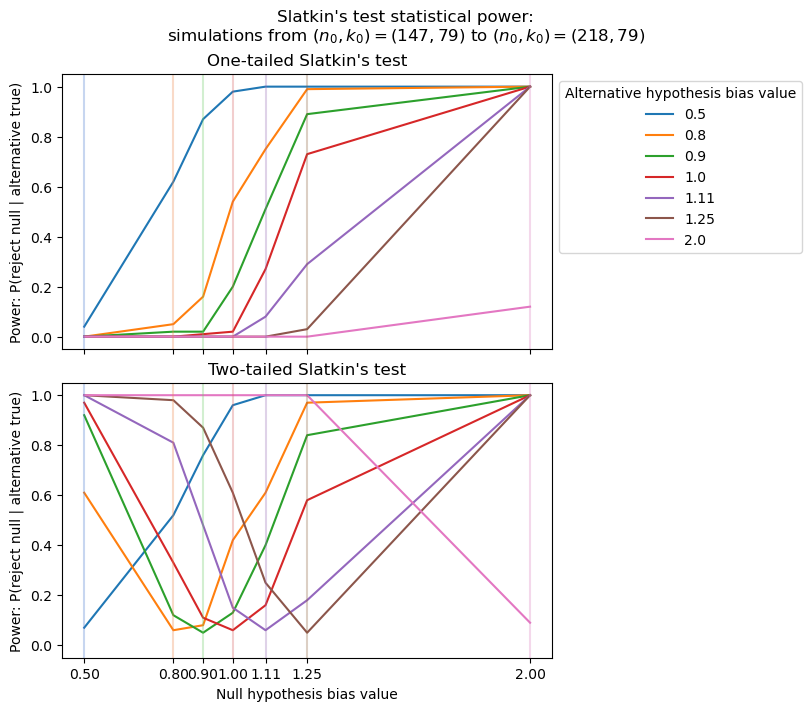

In [52]:
dplot = power_df.query("n == 218")
palette = sns.color_palette("muted", n_colors=7)
fig, axs = plt.subplots(
    2, 1, figsize=(8, 7), constrained_layout=True, sharex=True, sharey=True
)

ax = axs[0]
sns.lineplot(dplot, x="bias_test", y="onetail", hue="bias_gen", ax=ax)

biases = sorted(set(dplot["bias_test"]))
for i, x in enumerate(biases):
    ax.axvline(x=float(x), color=palette[i], alpha=0.3)

ax.set_xlabel("Null hypothesis bias value")
ax.set_ylabel("Power: P(reject null | alternative true)")
ax.set_xticks(biases)
ax.legend(
    title=("Alternative hypothesis bias value"), loc="upper left", bbox_to_anchor=(1, 1)
)
ax.set_title("One-tailed Slatkin's test")

ax = axs[1]
sns.lineplot(dplot, x="bias_test", y="twotail", hue="bias_gen", ax=ax, legend=False)

biases = sorted(set(power_df["bias_test"]))
for i, x in enumerate(biases):
    ax.axvline(x=float(x), color=palette[i], alpha=0.3)

ax.set_xlabel("Null hypothesis bias value")
ax.set_ylabel("Power: P(reject null | alternative true)")
ax.set_xticks(biases)
ax.set_title("Two-tailed Slatkin's test")

fig.suptitle(
    "Slatkin's test statistical power:\nsimulations from $(n_0,k_0) = (147, 79)$ to $(n_0,k_0) = (218, 79)$"
)

fig.savefig("statpower_grid_n71.pdf", bbox_inches="tight")
fig.savefig("statpower_grid_n71.png", dpi=600, bbox_inches="tight")

In [1]:
popes = pd.read_csv("popes-list.csv")


def run_biased_test_realdata(popes, s, size):
    e = s + size
    d = popes.query("start <= @s")

    year = d["start"].iloc[-1]
    pope = d["pope"].iloc[-1]
    initial_configuration = " ".join([str(x) for x in d["name"].value_counts()])
    n0 = d.shape[0]
    k0 = len(d["name"].unique())

    d_end = popes.query("start < @e")
    end_configuration = " ".join([str(x) for x in d_end["name"].value_counts()])
    n = d_end.shape[0]
    k = len(d_end["name"].unique())

    rows = []
    for bias in [0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.11, 1.25, 1.43, 1.67, 2]:
        p_tail = run_test_conditional_biased(
            n,
            k,
            end_configuration,
            initial_configuration,
            samples=100000,
            bias=bias,
            seed=int(n + k + bias * 1000),
        )
        rows.append(
            {
                "year": year,
                "pope": pope,
                "n": n,
                "k": k,
                "window_start": s,
                "window_end": e,
                "window_size": size,
                "n0": n0,
                "k0": k0,
                "bias": bias,
                "p_tail": p_tail,
            }
        )
    return pd.DataFrame.from_records(rows)


inputs = []
for size in [50, 100, 200]:
    for s in popes.query("start >= 432 and start < 2025 - @size + 5")["start"]:
        inputs.append((popes, s, size))

results = Parallel(n_jobs=-1)(delayed(run_biased_test_realdata)(*y) for y in inputs)

NameError: name 'pd' is not defined

In [41]:
realdata_biased = pd.concat(results)

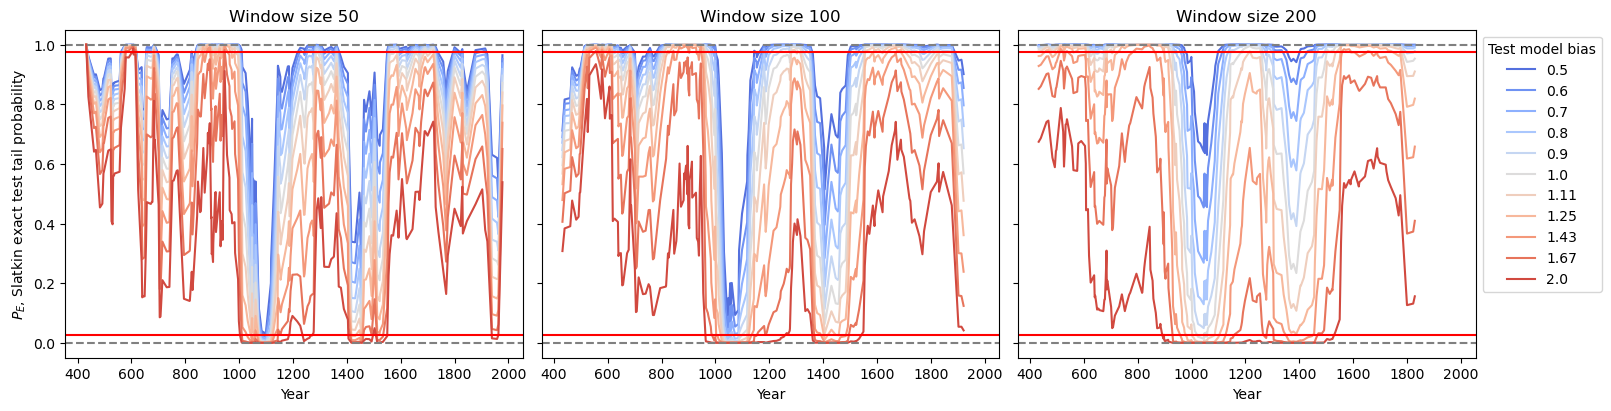

In [47]:
fig, axs = plt.subplots(
    1, 3, figsize=(16, 4), constrained_layout=True, sharex=True, sharey=True
)

for i, size in enumerate([50, 100, 200]):
    ax = axs[i]
    sns.lineplot(
        realdata_biased.query("window_size == @size"),
        x="window_start",
        y="p_tail",
        hue="bias",
        ax=ax,
        palette=sns.color_palette("coolwarm", n_colors=11),
        legend=True if i == 2 else False,
    )

    ax.set_xlabel("Year")
    ax.set_ylabel("$P_E$, Slatkin exact test tail probability")
    ax.axhline(0.025, color="red")
    ax.axhline(0.975, color="red")
    ax.axhline(1, color="gray", linestyle="--")
    ax.axhline(0, color="gray", linestyle="--")
    ax.set_title(f"Window size {size}")

axs[2].legend(title="Test model bias", loc="upper left", bbox_to_anchor=(1, 1))

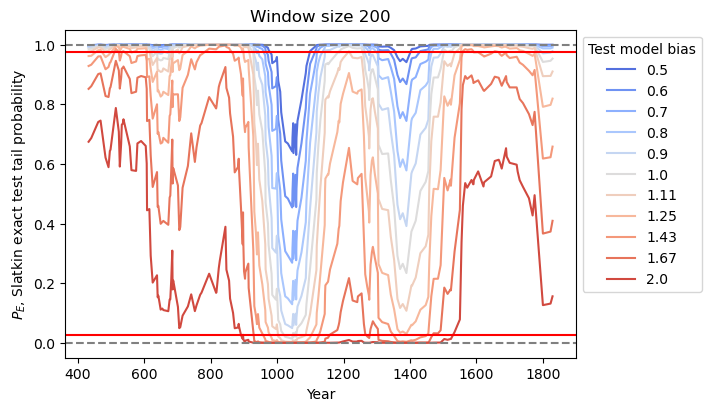

In [51]:
fig, ax = plt.subplots(
    1, figsize=(7, 4), constrained_layout=True, sharex=True, sharey=True
)

sns.lineplot(
    realdata_biased.query("window_size == 200"),
    x="window_start",
    y="p_tail",
    hue="bias",
    ax=ax,
    palette=sns.color_palette("coolwarm", n_colors=11),
)

ax.set_xlabel("Year")
ax.set_ylabel("$P_E$, Slatkin exact test tail probability")
ax.axhline(0.025, color="red")
ax.axhline(0.975, color="red")
ax.axhline(1, color="gray", linestyle="--")
ax.axhline(0, color="gray", linestyle="--")
ax.set_title(f"Window size {size}")

ax.legend(title="Test model bias", loc="upper left", bbox_to_anchor=(1, 1))

fig.savefig("biased_test_realdata.pdf", bbox_inches="tight")
fig.savefig("biased_test_realdata.png", bbox_inches="tight", dpi=600)

In [3]:
popes = pd.read_csv("popes-list.csv")


def run_power_windows(popes, s, size):
    e = s + size
    d = popes.query("start <= @s")

    year = d["start"].iloc[-1]
    pope = d["pope"].iloc[-1]
    initial_configuration = " ".join([str(x) for x in d["name"].value_counts()])
    n0 = d.shape[0]
    k0 = len(d["name"].unique())

    d_end = popes.query("start < @e")
    end_configuration = " ".join([str(x) for x in d_end["name"].value_counts()])
    n = d_end.shape[0]
    k = len(d_end["name"].unique())

    rows = []
    for bias in [0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.11, 1.25, 1.43, 1.67, 2]:
        for i, tc in enumerate(
            sample_configurations(
                n,
                k,
                initial_configuration,
                bias=bias,
                samples=100,
                seed=int(n + k + bias * 1000 + 2),
            )
        ):
            p_tail = run_test_conditional(
                n,
                k,
                tc,
                initial_configuration,
                samples=10000,
                seed=int(n + k + bias * 1000),
            )
            rows.append(
                {
                    "year": year,
                    "pope": pope,
                    "n": n,
                    "k": k,
                    "window_start": s,
                    "window_end": e,
                    "window_size": size,
                    "n0": n0,
                    "k0": k0,
                    "bias": bias,
                    "rep": i,
                    "sim_configuration": tc,
                    "p_tail": p_tail,
                }
            )
    return pd.DataFrame.from_records(rows)


inputs = []
for size in [200]:
    for s in popes.query("start >= 432 and start < 2025 - @size + 5")["start"]:
        inputs.append((popes, s, size))

results = Parallel(n_jobs=-1)(delayed(run_power_windows)(*y) for y in inputs)

In [6]:
power_windf = pd.concat(results)
power_windf.to_csv("power_windows.csv", index=False)

In [15]:
power_windf = (
    pd.read_csv("power_windows.csv")
    .groupby(["year", "pope", "n", "k", "window_start", "window_end", "bias"])
    .agg({"p_tail": ["count", onetail, twotail]})
    .reset_index()
)
power_windf.columns = [
    "year",
    "pope",
    "n",
    "k",
    "window_start",
    "window_end",
    "bias",
    "total",
    "onetail",
    "twotail",
]
power_windf["onetail"] = power_windf["onetail"] / power_windf["total"]
power_windf["twotail"] = power_windf["twotail"] / power_windf["total"]
# power_windf['bias'] = power_windf['bias'].astype(str)
power_windf

,year,pope,n,k,window_start,window_end,bias,total,onetail,twotail
0,432,Sixtus III,70,58,432,632,0.50,100,0.00,0.00
1,432,Sixtus III,70,58,432,632,0.60,100,0.00,0.00
2,432,Sixtus III,70,58,432,632,0.70,100,0.00,0.00
3,432,Sixtus III,70,58,432,632,0.80,100,0.00,0.00
4,432,Sixtus III,70,58,432,632,0.90,100,0.00,0.01
...,...,...,...,...,...,...,...,...,...,...
2118,1829,Pius VIII,265,81,1829,2029,1.11,100,0.02,0.06
2119,1829,Pius VIII,265,81,1829,2029,1.25,100,0.00,0.11
2120,1829,Pius VIII,265,81,1829,2029,1.43,100,0.00,0.23
2121,1829,Pius VIII,265,81,1829,2029,1.67,100,0.00,0.58


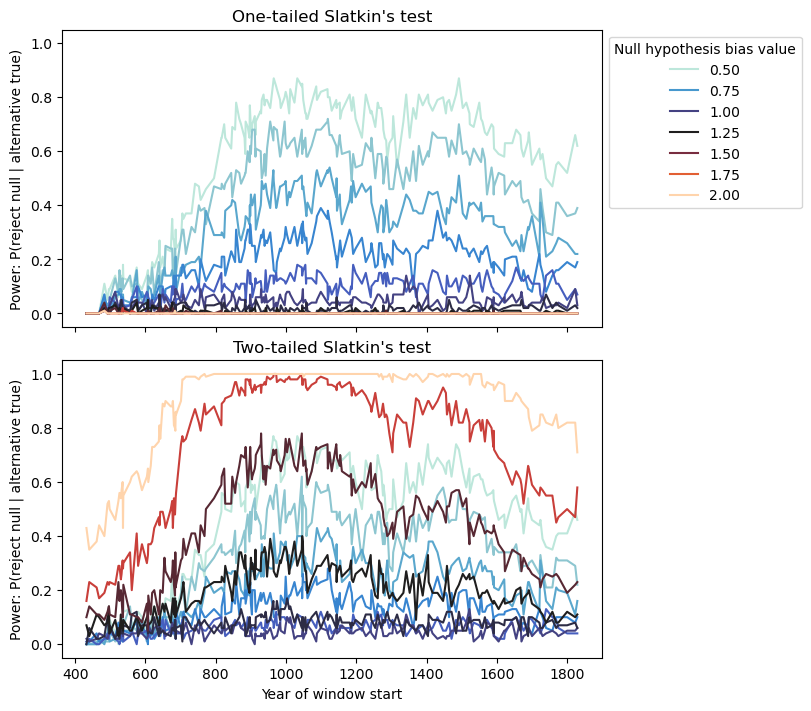

In [19]:
palette = sns.color_palette("muted", n_colors=7)
fig, axs = plt.subplots(
    2, 1, figsize=(8, 7), constrained_layout=True, sharex=True, sharey=True
)

ax = axs[0]
sns.lineplot(
    power_windf,
    x="window_start",
    y="onetail",
    hue="bias",
    ax=ax,
    palette=sns.color_palette("icefire", as_cmap=True),
)

ax.set_xlabel("Year of window start")
ax.set_ylabel("Power: P(reject null | alternative true)")
ax.legend(title=("Null hypothesis bias value"), loc="upper left", bbox_to_anchor=(1, 1))
ax.set_title("One-tailed Slatkin's test")

ax = axs[1]
sns.lineplot(
    power_windf,
    x="year",
    y="twotail",
    hue="bias",
    ax=ax,
    legend=False,
    palette=sns.color_palette("icefire", as_cmap=True),
)

ax.set_xlabel("Year of window start")
ax.set_ylabel("Power: P(reject null | alternative true)")
ax.set_title("Two-tailed Slatkin's test")

fig.savefig("statpower_windows_200.pdf", bbox_inches="tight")
fig.savefig("statpower_windows_200.png", dpi=600, bbox_inches="tight")